In [1]:
import numpy as np
import tensorflow as tf
import catppuccin
import matplotlib.pyplot as plt
import matplotx
import pandas as pd
from pathlib import Path

tf.config.set_visible_devices([], "GPU")
plt.style.use(matplotx.styles.github['light'])
DATA_DIR = Path("data")

In [2]:
Y = pd.read_csv(DATA_DIR / "small_movies_Y.csv", header=None).to_numpy()
R = pd.read_csv(DATA_DIR / "small_movies_R.csv", header=None).to_numpy()
movie_df = pd.read_csv(DATA_DIR / "small_movie_list.csv", index_col=0).to_numpy()
X = pd.read_csv(DATA_DIR / "small_movies_X.csv", header=None).to_numpy()
W = pd.read_csv(DATA_DIR / "small_movies_W.csv", header=None).to_numpy()
b = pd.read_csv(DATA_DIR / "small_movies_b.csv", header=None).to_numpy()

print("ratings_df:", Y.shape)
print("rated_df:", R.shape)
print("movie_df:", movie_df.shape)
print("movie_features_df:", X.shape)
print("user_features_df:", W.shape)
print("user_bias_df:", b.shape)

ratings_df: (4778, 443)
rated_df: (4778, 443)
movie_df: (4778, 3)
movie_features_df: (4778, 10)
user_features_df: (443, 10)
user_bias_df: (1, 443)


In [3]:
movie_df

array([[3.4, 5, 'Yards, The (2000)'],
       [3.25, 6, 'Next Friday (2000)'],
       [2.0, 4, 'Supernova (2000)'],
       ...,
       [3.5, 1, 'No Game No Life: Zero (2017)'],
       [3.5, 1, 'Flint (2017)'],
       [3.5, 1, 'Bungo Stray Dogs: Dead Apple (2018)']], dtype=object)

In [4]:
num_movies, num_features = X.shape
num_users, num_features = W.shape

print(num_movies, num_users, num_features)
X

4778 443 10


array([[-0.03328682,  1.1667464 , -0.5064895 , ..., -0.349303  ,
         0.75385165, -0.20810875],
       [ 0.40405777,  2.2664917 , -0.7428241 , ..., -1.0381029 ,
        -2.3322656 , -2.343191  ],
       [ 0.02347802,  0.42810223, -0.4263811 , ..., -0.29378366,
         0.43972966,  1.823422  ],
       ...,
       [-0.43808308,  0.71181   , -0.29844946, ...,  0.14841312,
        -0.439178  , -0.06239507],
       [ 1.1371753 ,  0.8651963 ,  1.0665106 , ...,  0.61943984,
         0.37744495, -3.4115074 ],
       [ 1.4329183 , -1.5280124 ,  1.0317537 , ...,  0.8750148 ,
         0.28633314,  0.46209347]])

Scream 3 (2000)  —  mean 2.67/5 from 29 ratings | user 1 rated 26 movies
|x|=2.384  |w|=0.992  angle=89.0°  x·w=+0.0409  bias=+0.3565  no Ymean (normalised scale)
predicted 0.50   (not rated by this user)
  note: raw 0.40 clipped into (0.5, 5.0)


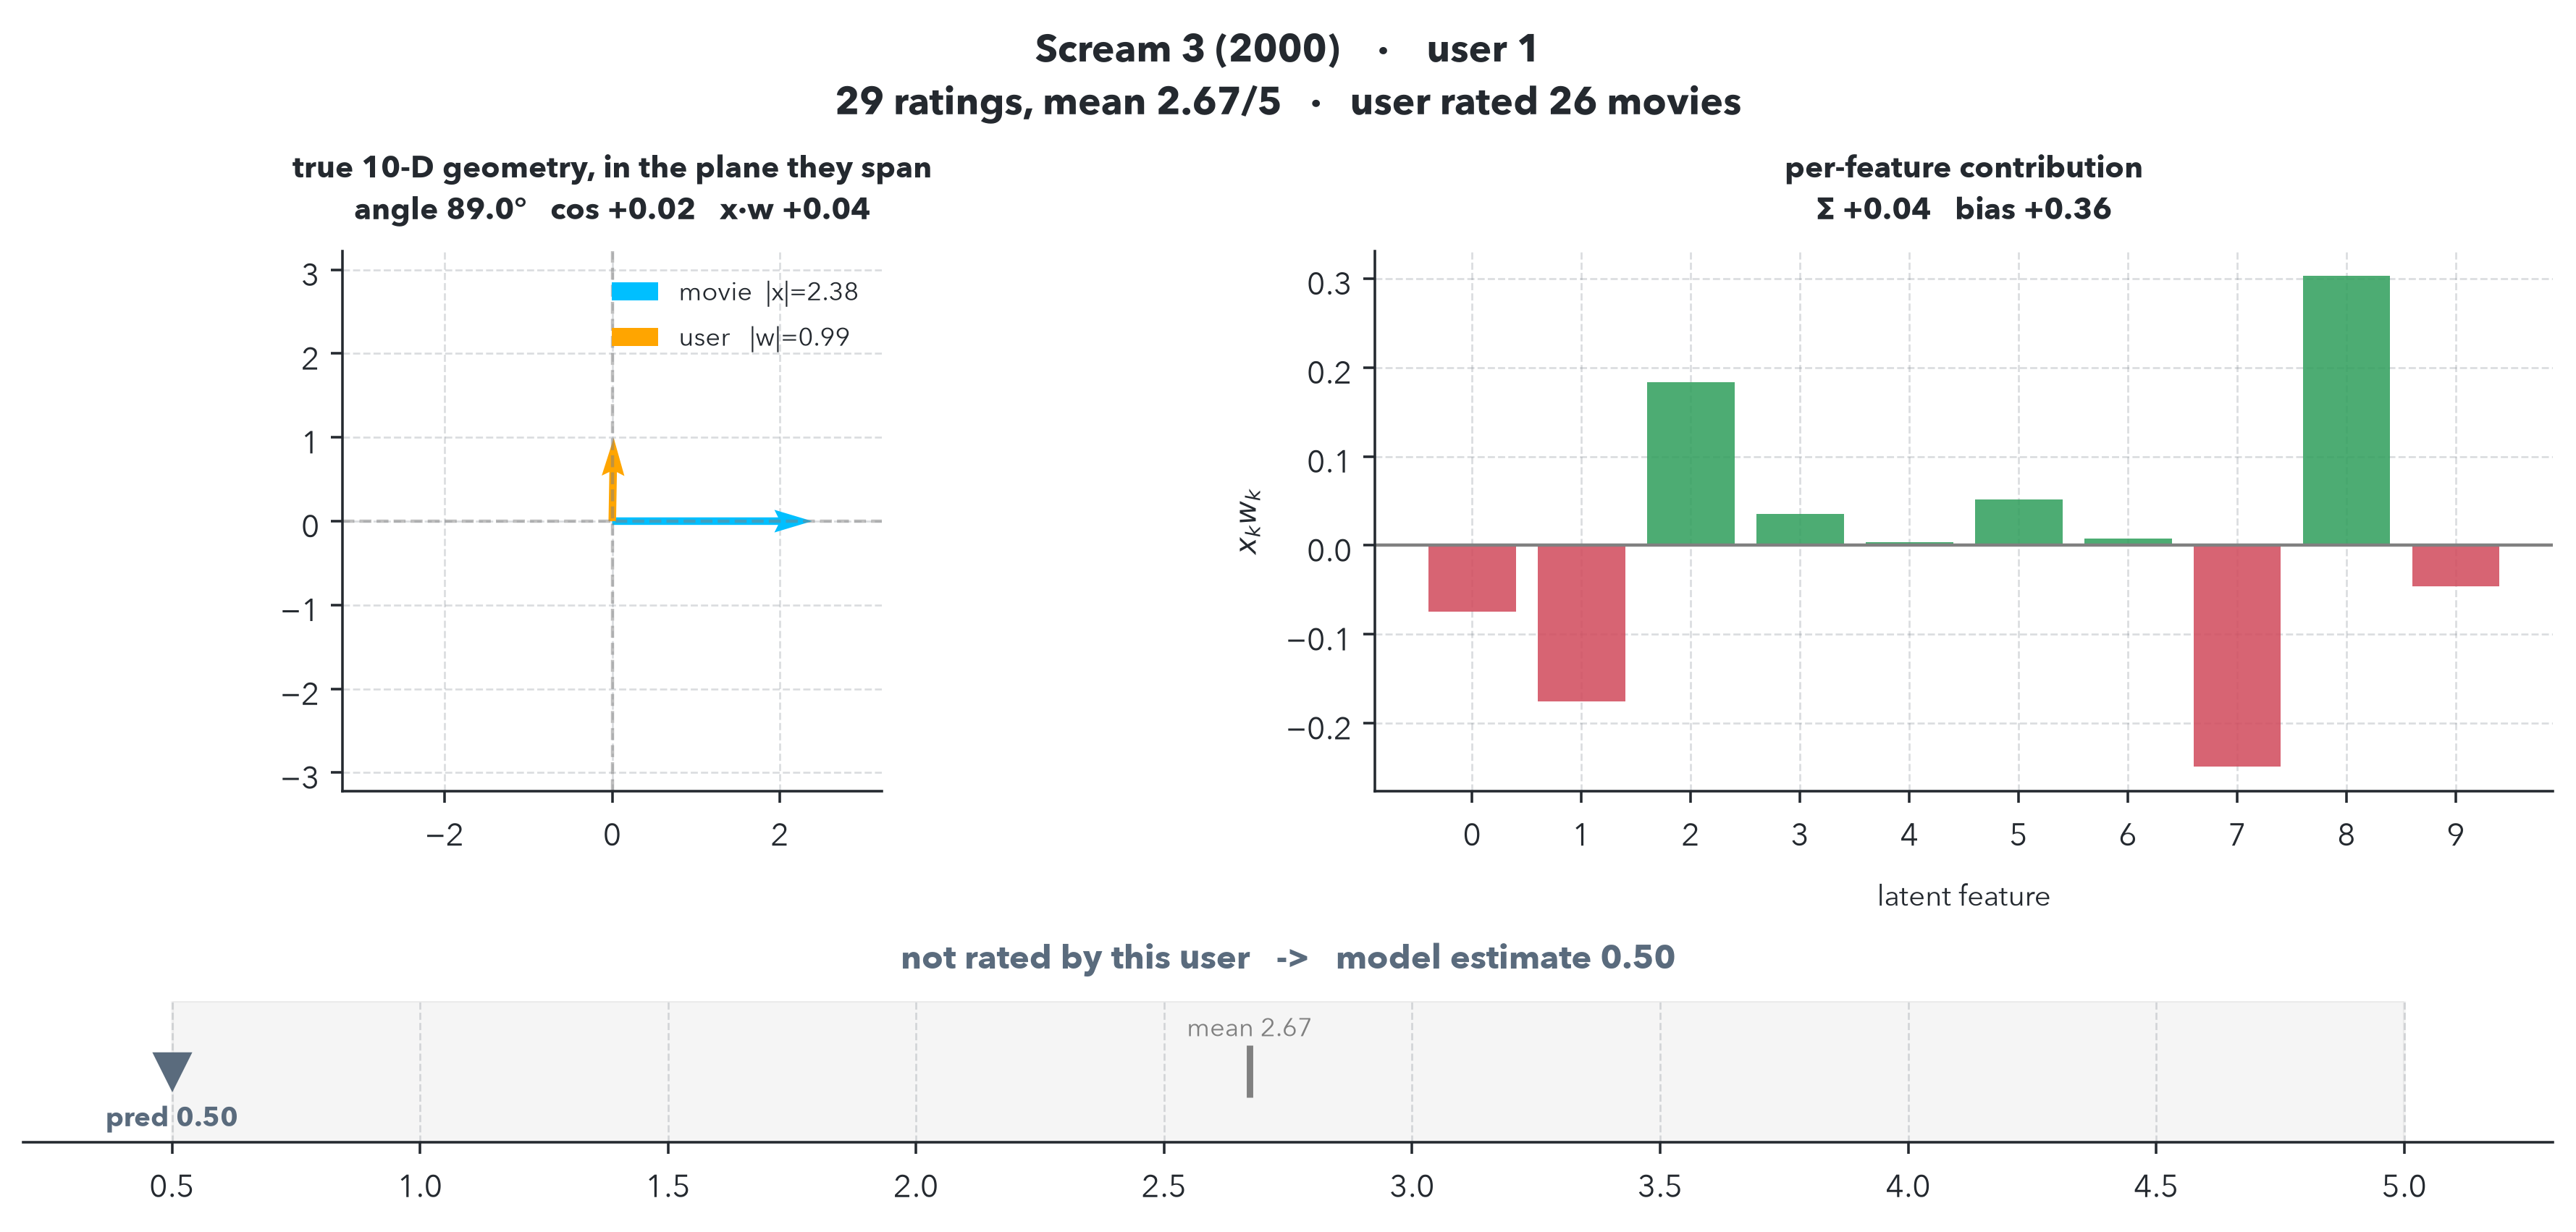

{'pred': 0.5,
 'actual': None,
 'error': None,
 'rated': False,
 'cos': 0.017285323801908226,
 'angle_deg': np.float64(89.0095745741737),
 'contrib': array([-0.07413383, -0.1751116 ,  0.1832455 ,  0.03575401,  0.00341155,
         0.05124869,  0.00807168, -0.24849794,  0.3029929 , -0.0461082 ]),
 'bias': 0.35653394}

In [5]:
def _np(a):
    """tf.Variable / tf.Tensor / ndarray -> float ndarray"""
    return np.asarray(a.numpy() if hasattr(a, "numpy") else a, dtype=float)

def test_plot(movieidx, useridx, Ymean=None, clip=(0.5, 5.0)):
    m     = _np(X[movieidx])
    u     = _np(W[useridx])
    b_val = float(_np(b)[0, useridx])

    contrib = m * u                     # per-feature contribution to the dot product
    # The precomputed params are fit on MEAN-NORMALISED ratings, so the movie mean
    # has to be added back to land on the 0.5-5 scale. Pass Ymean to do that.
    offset   = float(np.ravel(_np(Ymean))[movieidx]) if Ymean is not None else 0.0
    pred_raw = contrib.sum() + b_val + offset
    pred     = float(np.clip(pred_raw, *clip)) if clip else pred_raw

    rated  = bool(R[movieidx, useridx])
    actual = float(Y[movieidx, useridx]) if rated else None
    err    = abs(pred - actual) if rated else None

    title  = str(movie_df[movieidx, 2])
    mean_r = float(movie_df[movieidx, 0])
    n_r    = int(movie_df[movieidx, 1])
    n_user = int(R[:, useridx].sum())

    # --- exact 2-D plane spanned by m and u (Gram-Schmidt) -------------------
    # Unlike slicing the first two features, the lengths, angle and dot product
    # drawn here are the true n-dimensional ones.
    e1 = m / (np.linalg.norm(m) or 1.0)
    r  = u - (u @ e1) * e1
    nr = np.linalg.norm(r)
    e2 = r / nr if nr > 1e-12 else np.zeros_like(e1)
    m2, u2 = np.array([m @ e1, m @ e2]), np.array([u @ e1, u @ e2])
    denom  = np.linalg.norm(m) * np.linalg.norm(u)
    cos_t  = float(m @ u / denom) if denom > 1e-12 else 0.0
    theta  = np.degrees(np.arccos(np.clip(cos_t, -1, 1)))

    scale_note = f"+Ymean={offset:.2f}" if Ymean is not None else "no Ymean (normalised scale)"
    print(f"{title}  —  mean {mean_r:.2f}/5 from {n_r} ratings | user {useridx} rated {n_user} movies")
    print(f"|x|={np.linalg.norm(m):.3f}  |w|={np.linalg.norm(u):.3f}  angle={theta:.1f}°  "
          f"x·w={m@u:+.4f}  bias={b_val:+.4f}  {scale_note}")
    print(f"predicted {pred:.2f}" + (f"   actual {actual:.1f}   error {err:.2f}"
                                     if rated else "   (not rated by this user)"))
    if clip and abs(pred_raw - pred) > 1e-9:
        print(f"  note: raw {pred_raw:.2f} clipped into {clip}")

    good = rated and err <= 0.5
    col  = "#2e9e5b" if good else ("#d1495b" if rated else "#5a6b7d")

    fig = plt.figure(figsize=(11, 5.2), constrained_layout=True)
    gs  = fig.add_gridspec(2, 2, height_ratios=[4, 1.05])
    axv, axc = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])
    axs = fig.add_subplot(gs[1, :])

    # ---- left: the two vectors, in their own exact plane ----
    axv.quiver(0, 0, *m2, angles="xy", scale_units="xy", scale=1, color="deepskyblue",
               width=.014, label=f"movie  |x|={np.linalg.norm(m):.2f}")
    axv.quiver(0, 0, *u2, angles="xy", scale_units="xy", scale=1, color="orange",
               width=.014, label=f"user   |w|={np.linalg.norm(u):.2f}")
    lim = (max(np.abs(np.concatenate([m2, u2]))) or 1.0) * 1.35
    axv.set(xlim=(-lim, lim), ylim=(-lim, lim), aspect="equal")
    axv.axhline(0, color="gray", ls="--", lw=1, alpha=.5)
    axv.axvline(0, color="gray", ls="--", lw=1, alpha=.5)
    axv.grid(alpha=.25)
    axv.set_title(f"true {len(m)}-D geometry, in the plane they span\n"
                  f"angle {theta:.1f}°   cos {cos_t:+.2f}   x·w {m@u:+.2f}", fontsize=9.5)
    axv.legend(loc="upper right", fontsize=8, framealpha=.9)

    # ---- right: what actually produces the number ----
    k = np.arange(len(contrib))
    axc.bar(k, contrib, color=np.where(contrib >= 0, "#2e9e5b", "#d1495b"), alpha=.85)
    axc.axhline(0, color="gray", lw=1)
    axc.set_xticks(k)
    axc.set_xlabel("latent feature", fontsize=9)
    axc.set_ylabel("$x_k w_k$", fontsize=9)
    axc.grid(alpha=.25, axis="y")
    axc.set_title("per-feature contribution\n"
                  f"Σ {contrib.sum():+.2f}   bias {b_val:+.2f}"
                  + (f"   mean {offset:+.2f}" if Ymean is not None else ""), fontsize=9.5)

    # ---- bottom: the rating line ----
    axs.set(xlim=(0.2, 5.3), ylim=(0, 1), yticks=[], xticks=np.arange(.5, 5.5, .5))
    axs.grid(alpha=.25, axis="x")
    axs.axvspan(.5, 5., color="gray", alpha=.08)
    for sp in ("left", "right", "top"): axs.spines[sp].set_visible(False)
    if rated:
        axs.plot([min(pred, actual), max(pred, actual)], [.5, .5], color=col, lw=4, alpha=.45)
    axs.plot([mean_r], [.5], marker="|", ms=16, mew=2, color="gray")
    axs.annotate(f"mean {mean_r:.2f}", (mean_r, .5), textcoords="offset points",
                 xytext=(0, 11), ha="center", fontsize=8, color="gray")
    axs.plot([pred], [.5], marker="v", ms=11, color=col, zorder=3)
    axs.annotate(f"pred {pred:.2f}", (pred, .5), textcoords="offset points",
                 xytext=(0, -17), ha="center", fontsize=8.5, color=col, weight="bold")
    if rated:
        axs.plot([actual], [.5], marker="o", ms=10, mfc="none", mec="black", mew=1.8, zorder=3)
        axs.annotate(f"actual {actual:.1f}", (actual, .5), textcoords="offset points",
                     xytext=(0, 11), ha="center", fontsize=8.5, weight="bold")
    axs.set_title((f"rated {actual:.1f}   ->   predicted {pred:.2f}   (error {err:.2f})" if rated
                   else f"not rated by this user   ->   model estimate {pred:.2f}"),
                  fontsize=10.5, color=col, weight="bold")

    fig.suptitle(f"{title}    ·    user {useridx}\n"
                 f"{n_r} ratings, mean {mean_r:.2f}/5   ·   user rated {n_user} movies",
                 fontsize=12, weight="bold")
    plt.show()
    return {"pred": pred, "actual": actual, "error": err, "rated": rated,
            "cos": cos_t, "angle_deg": theta, "contrib": contrib, "bias": b_val}
test_plot(4, 1)

X = movie features \
no. of movie features = 10
$$
\begin{align}
\hat{Y} &= X \times W^T + b \\
L_2 &= \frac{\lambda}{2} \left( \sum W^2 + \sum X^2 \right) \\
J &= \frac{1}{2} \sum \left(\hat{Y}^2 - Y\right) + L_2
\end{align}
$$

In [6]:
X.shape, W.shape, Y.shape, b.shape
# X * W^T + b

def J(l):
    Y_cap = X @ tf.transpose(W) + b

    l2 = .5 * l * (tf.reduce_sum(tf.square(W)) + tf.reduce_sum(tf.square(X)))
    err = .5 * tf.reduce_sum(tf.square(Y_cap - Y) * R) + l2
    return err

J(0)

<tf.Tensor: shape=(), dtype=float64, numpy=270821.25400262704>

In [7]:
my_ratings = np.zeros(num_movies)
num_users += 1

# harry potter films
my_ratings[366] = 4
my_ratings[622] = 3
my_ratings[1051] = 4.5
my_ratings[1521] = 4
my_ratings[1930] = 3.5
my_ratings[2455] = 4
my_ratings[2804] = 4.5
my_ratings[2967] = 5

my_ratings[3915] = 4.8
my_ratings[3927] = 5
my_ratings[2700] = 2.8
my_ratings[2716] = 5
my_ratings[3618] = 4.5
my_ratings[3686] = 5
my_ratings[3697] = 2
my_ratings[3911] = 4.8
my_ratings[2663] = 4.8
my_ratings[2901] = 5
my_ratings[3245] = 5
my_ratings[4565] = 4.5
my_ratings[4203] = 4.8

my_rated = [i for i in range(len(my_ratings)) if my_ratings[i] > 0]

# Reload ratings
Y = np.c_[my_ratings, Y]
R = np.c_[(my_ratings != 0).astype(int), R]

In [8]:
tf.random.set_seed(1234)
num_features = 250
W = tf.Variable(tf.random.normal((num_users, num_features), dtype = tf.float64), name = "W")
X = tf.Variable(tf.random.normal((num_movies, num_features), dtype = tf.float64), name = "X")
b = tf.Variable(tf.random.normal((1, num_users), dtype = tf.float64), name = "b")

optimizer = tf.keras.optimizers.Adam(learning_rate= 1e-1)

In [9]:
# List to store the cost values for plotting
J_history = []

# Training
itrs = 2000
lambda_ = 1

@tf.function
def train_step():
    with tf.GradientTape() as tape:
        cost_value = J(lambda_)
    grads = tape.gradient(cost_value, [X, W, b])
    optimizer.apply_gradients(zip(grads, [X, W, b]))

    return cost_value

for itr in range(itrs + 1):
    cost_value = train_step()

    # Append the numpy value of the cost to our history list
    J_history.append(cost_value.numpy())

    # Print every 200 iterations to avoid output spam
    if itr % 200 == 0:
        print(f"Training loss at iteration {itr}: {cost_value.numpy():0.1f}")

Training loss at iteration 0: 5966074.1
Training loss at iteration 200: 9426.2
Training loss at iteration 400: 2808.3
Training loss at iteration 600: 2150.9
Training loss at iteration 800: 2059.1
Training loss at iteration 1000: 2043.2
Training loss at iteration 1200: 2038.2
Training loss at iteration 1400: 2036.2
Training loss at iteration 1600: 2035.3
Training loss at iteration 1800: 2034.9
Training loss at iteration 2000: 2034.7


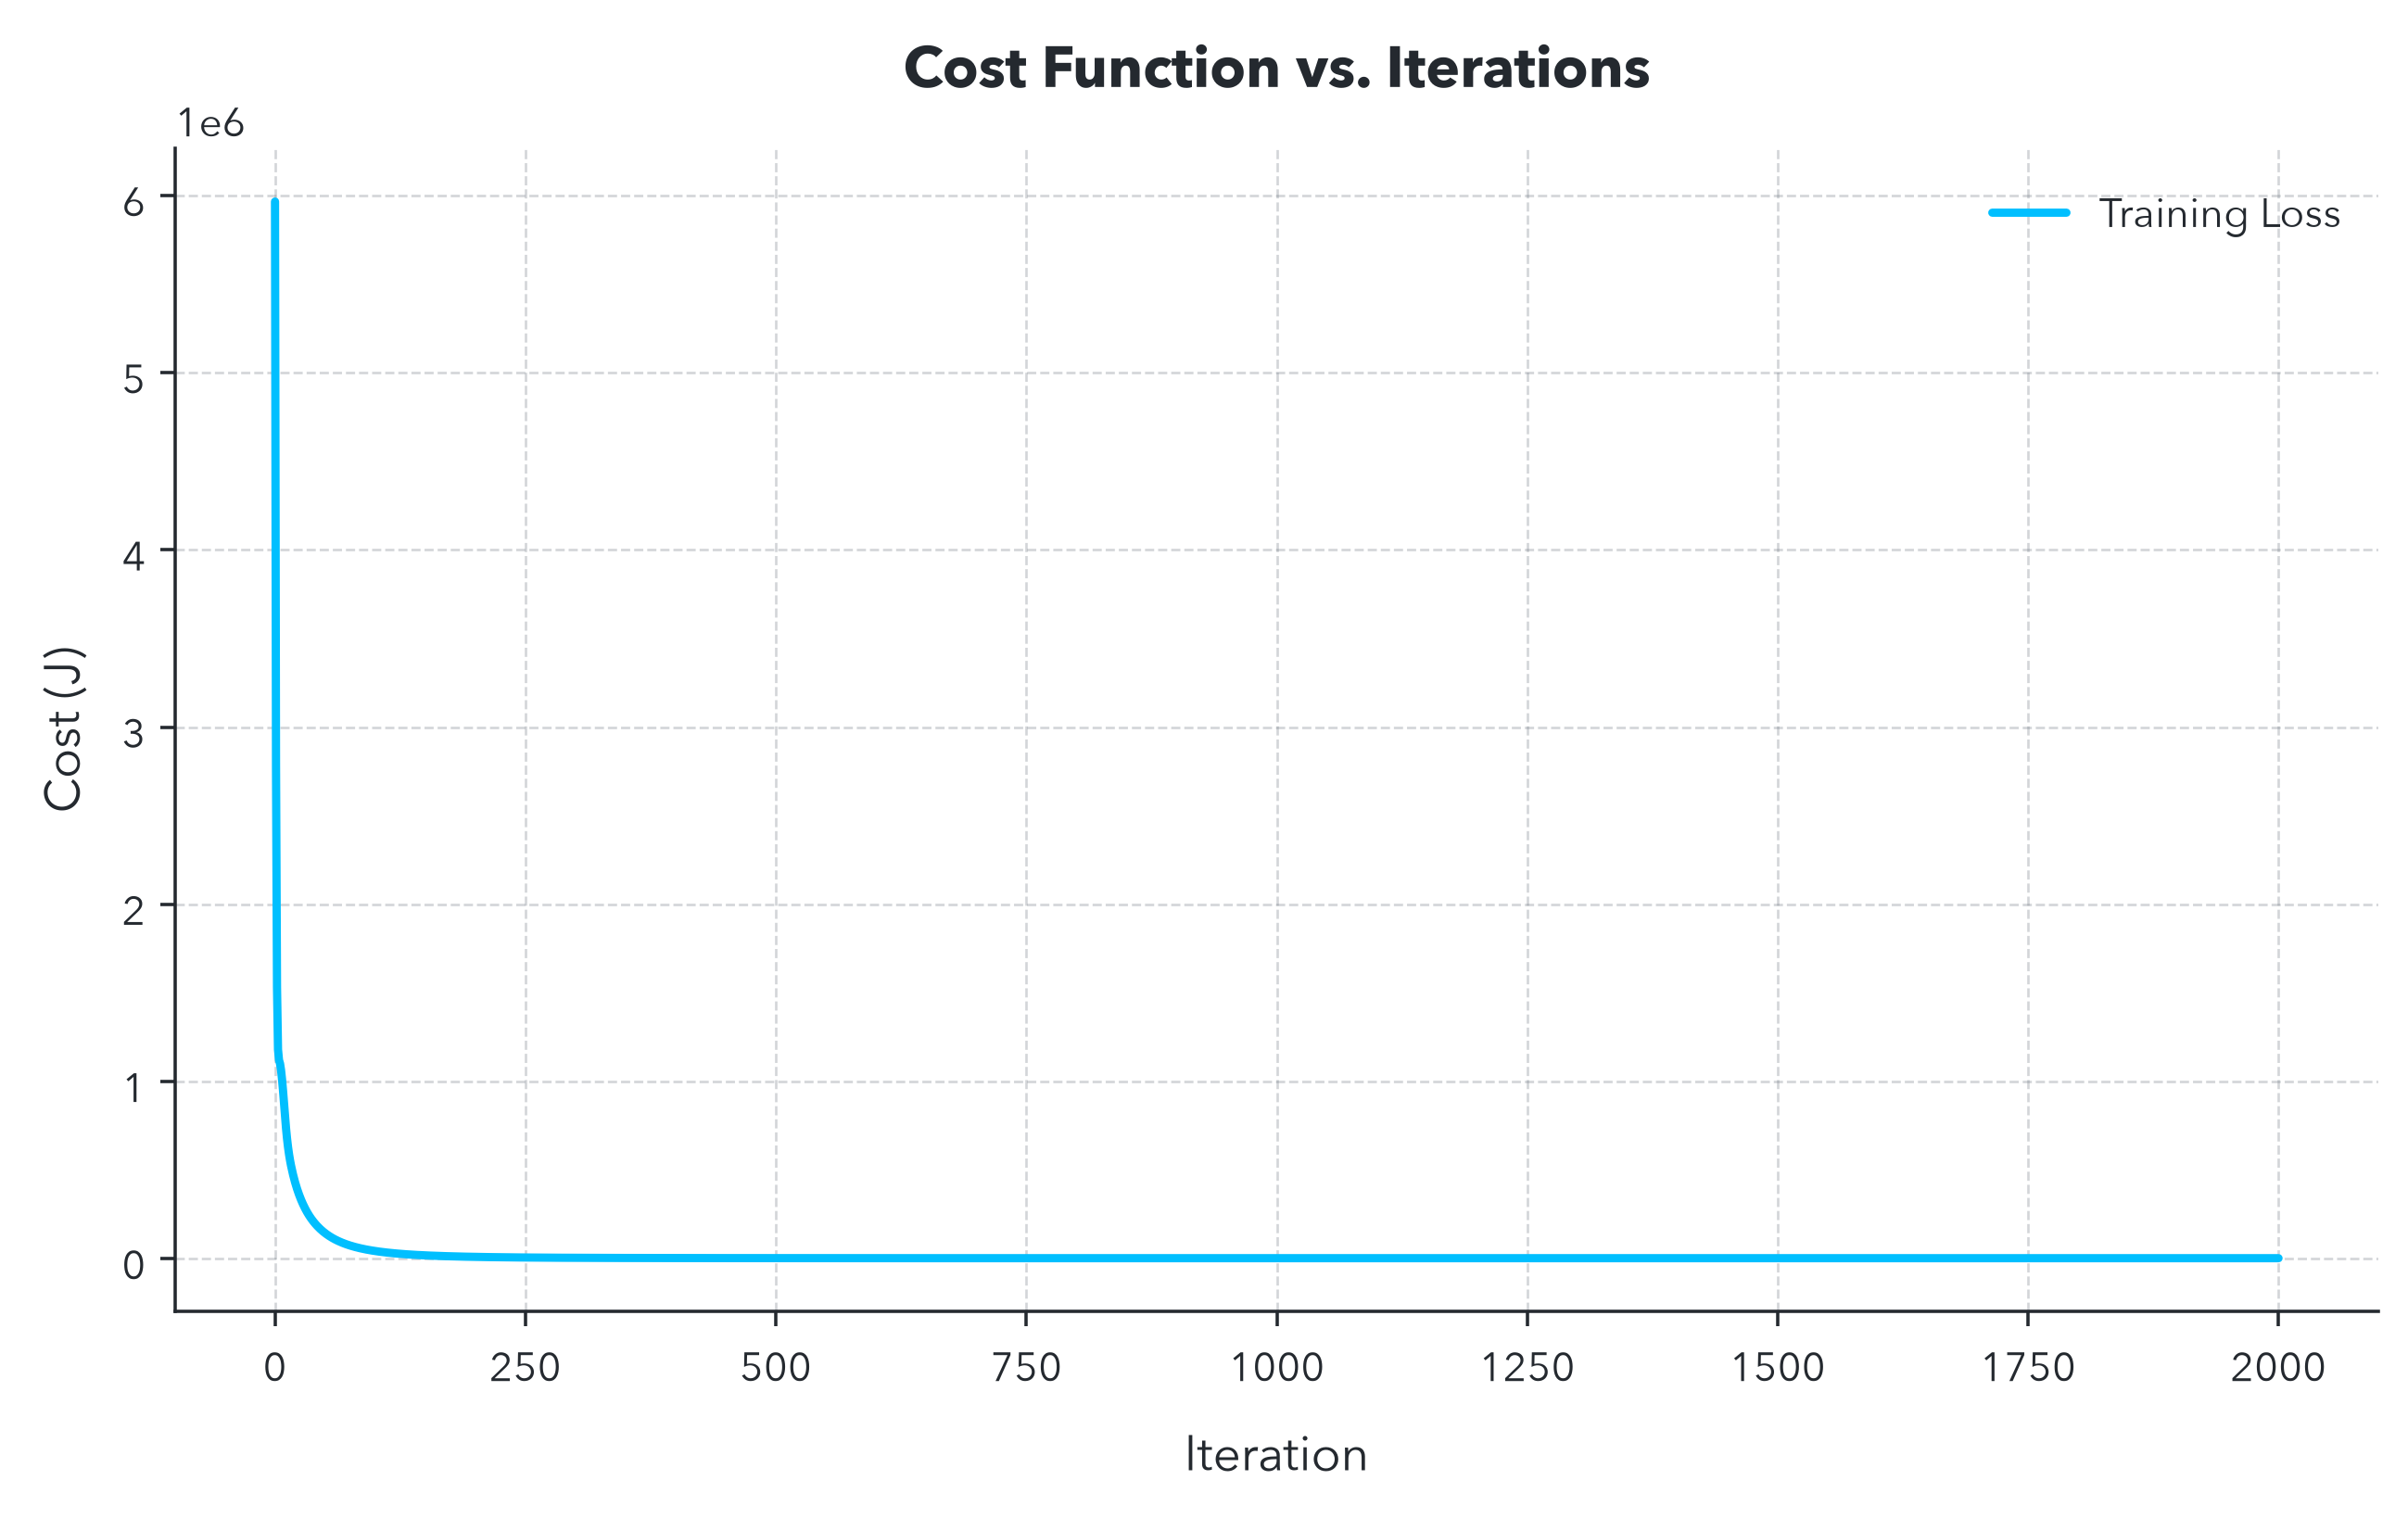

In [10]:
J_history = np.array(J_history)

# Plotting the Learning Curve
fig, ax = plt.subplots(1, 1, figsize=(8, 5))

# Using 'deepskyblue' to match your high-contrast theme preference
ax.plot(J_history, color='deepskyblue', linewidth=2, label="Training Loss")

ax.set_title("Cost Function vs. Iterations", pad=15, fontsize=14)
ax.set_xlabel("Iteration", fontsize=12)
ax.set_ylabel("Cost (J)", fontsize=12)

# Faint grid for readability without overwhelming the dark theme
ax.grid(True, alpha=0.3, linestyle='--')
ax.legend()

Despicable Me 3 (2017)  —  mean 2.25/5 from 2 ratings | user 0 rated 21 movies
|x|=0.495  |w|=1.476  angle=91.2°  x·w=-0.0148  bias=+4.4067  no Ymean (normalised scale)
predicted 4.39   (not rated by this user)


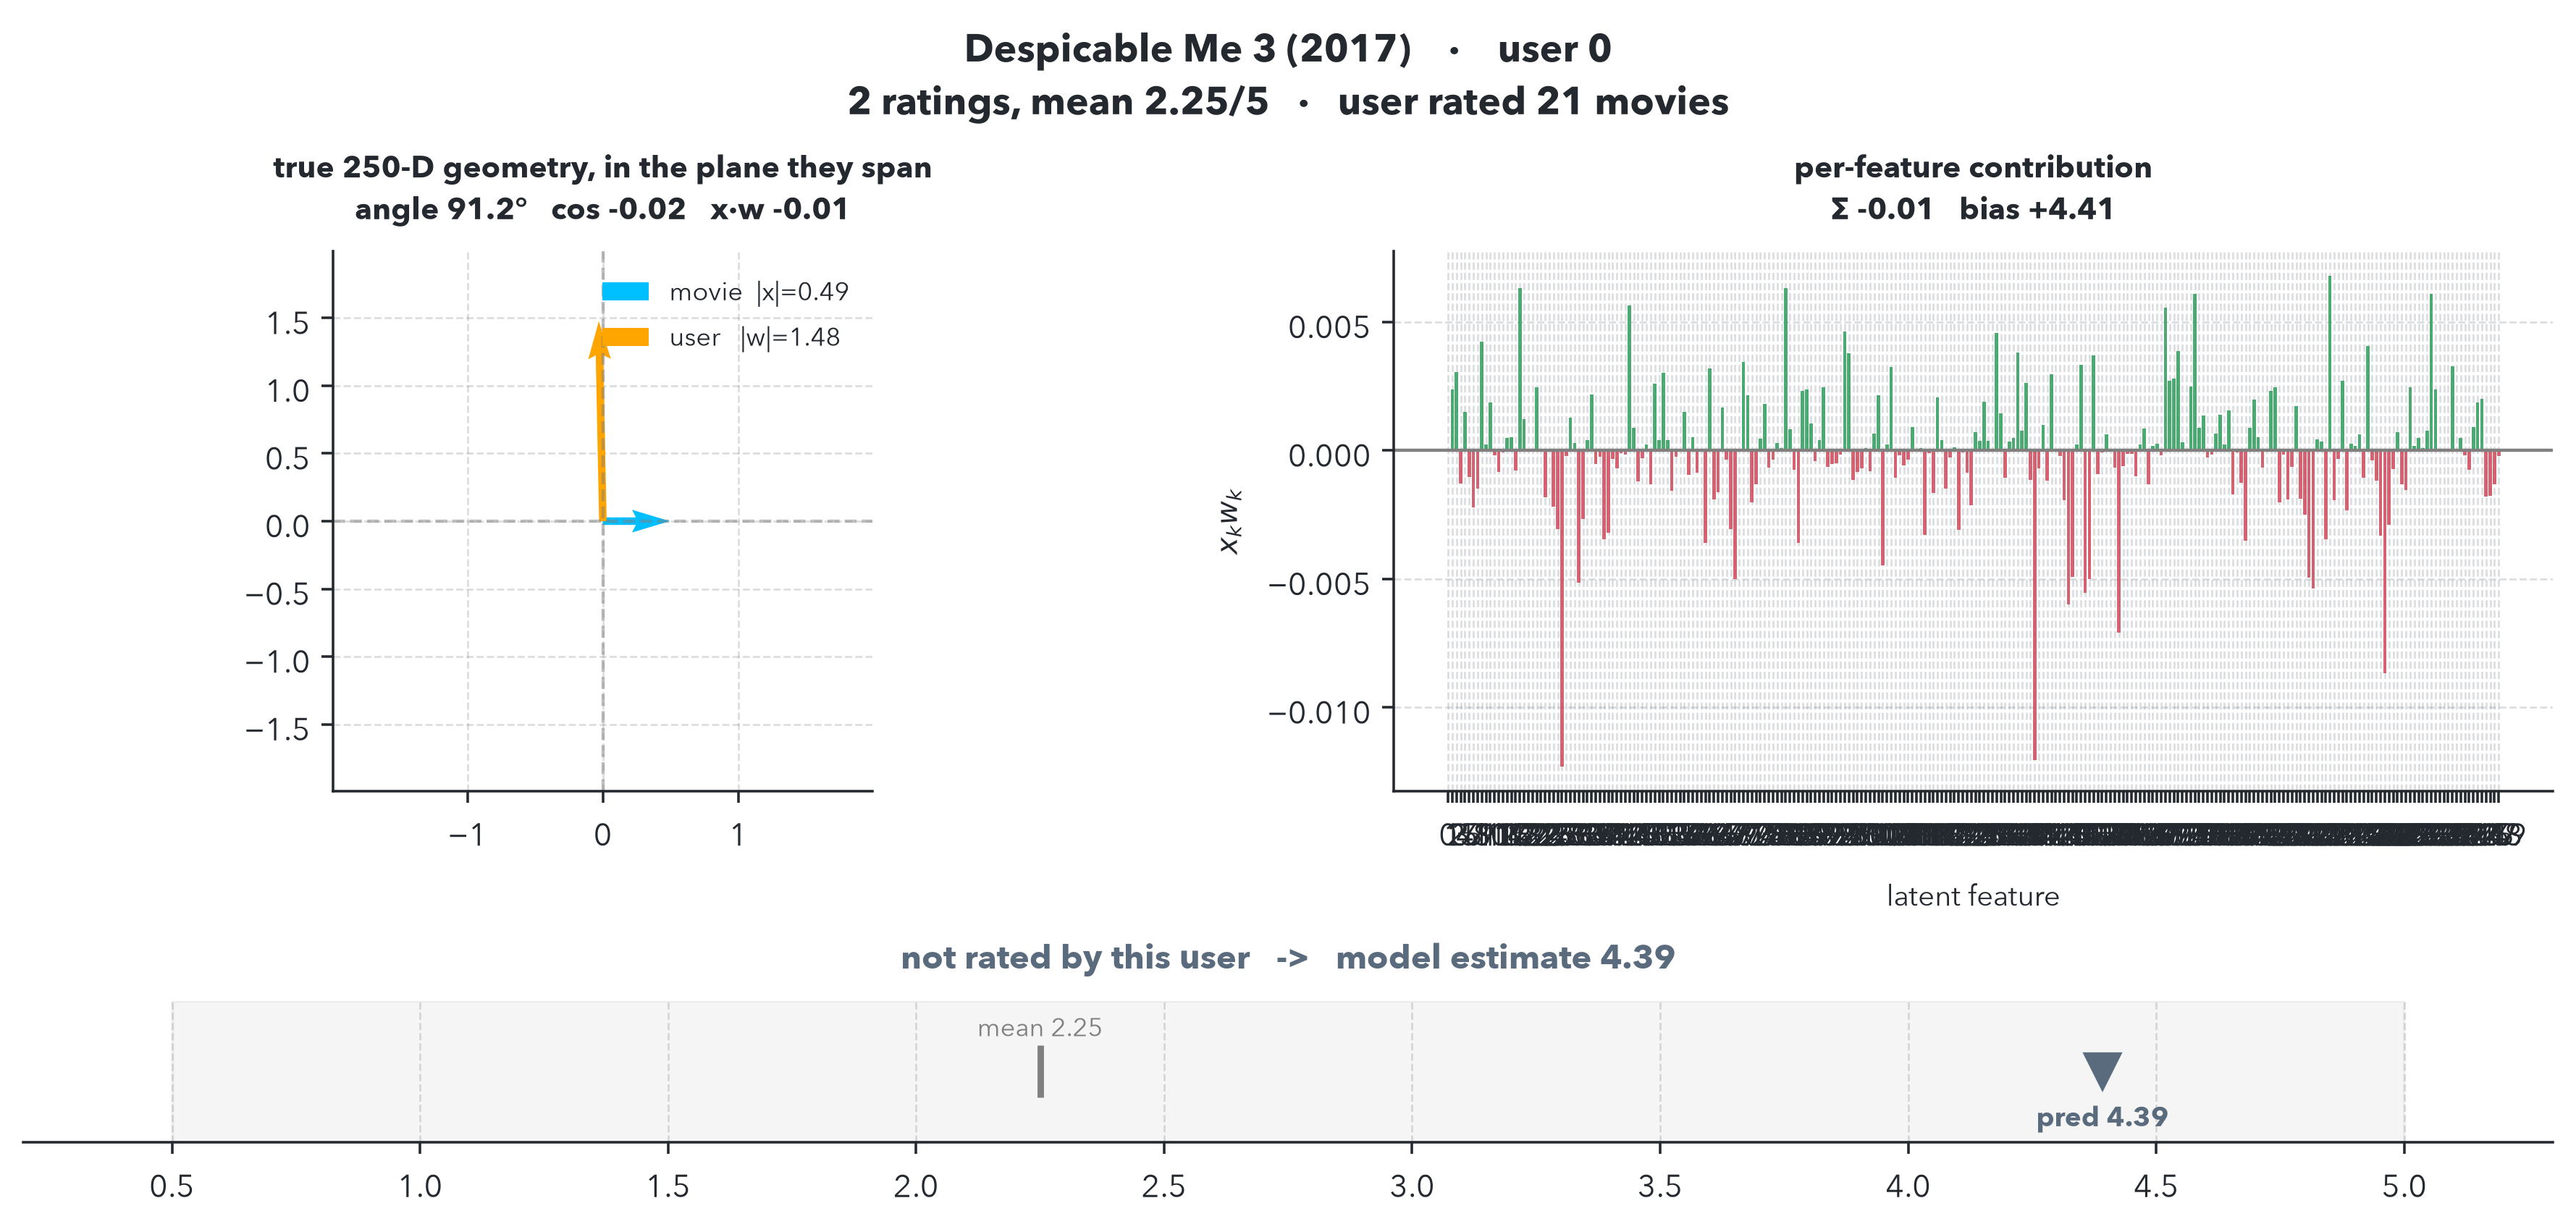

{'pred': 4.391951561310619,
 'actual': None,
 'error': None,
 'rated': False,
 'cos': -0.020267220412083838,
 'angle_deg': np.float64(91.1613057043602),
 'contrib': array([ 2.19669970e-05,  2.39118252e-03,  3.05199859e-03, -1.27143347e-03,
         1.51093930e-03, -1.03779084e-03, -2.21765191e-03, -1.47302550e-03,
         4.24043735e-03,  2.44418468e-04,  1.86128227e-03, -1.93110718e-04,
        -8.31553623e-04, -6.60321998e-05,  4.79226046e-04,  5.13504290e-04,
        -7.83627043e-04,  6.32936792e-03,  1.23164681e-03, -4.75453494e-05,
         2.65525109e-05,  2.47019375e-03, -2.43453661e-05, -1.82657300e-03,
         4.75428024e-05, -2.19229616e-03, -3.06082600e-03, -1.22935641e-02,
        -2.11857679e-04,  1.28046442e-03,  3.02891043e-04, -5.14146529e-03,
        -2.67162704e-03,  3.96925086e-04,  2.17204974e-03, -5.25587631e-04,
        -2.46988596e-04, -3.44563644e-03, -3.19666391e-03, -3.28842130e-04,
        -7.04605967e-04, -8.87622436e-05, -1.47443184e-04,  5.65568132e-03,


In [11]:
test_plot(4610, 0)

In [12]:
print(X[:, :2].shape)
vectors = X[:, :2] # (movie, 250)
print(my_ratings.shape)

for movie in range(num_movies):
    vec = vectors[movie, :]
    pred = np.dot(X[movie], W[0]) + b[0][0]
    c = "deepskyblue"
    if pred < 3.5: c = "red"
    if pred >= 4.8 and my_ratings[movie] == 0:
        c = "lightgreen"
        print(movie_df[movie][2], float(pred))

(4778, 2)
(4778,)
Snow Day (2000) 4.827623250460041
Memento (2000) 4.948826753757761
Joe Dirt (2001) 4.864563646364232
Fast and the Furious, The (2001) 4.95140979265193
Mulholland Drive (2001) 4.851033847778061
Donnie Darko (2001) 4.839161876732766
Gosford Park (2001) 4.804403811569657
Matrix Revolutions, The (2003) 4.959734537122799
Social Network, The (2010) 4.872754590032242
Fighter, The (2010) 4.853563580651521
